# 04 · Macro internacional (bloque 4) y curvas oficiales (bloque 6)

Este notebook recorre las series que el **bloque 4** añade a la base: BCE y Eurostat (zona euro), BIS, FMI (WEO),
Banco Mundial, OCDE (ediciones de *Short-term economic statistics revisions*), Philadelphia Fed (RTDSM, solo los
vintages anteriores a ALFRED) y bancos centrales (BoC, BoJ, Bundesbank, RBA), junto con las curvas oficiales del
**bloque 6** (Tesoro de EE. UU., BCE, MoF de Japón, BoC y BoE). Todas tienen el mismo contrato que las de FRED:
`fecha_publicacion` es la primera decisión (16:30 de Nueva York) en la que el dato era visible, y las revisables
llevan su vintage (ediciones de la OCDE, versiones del BCE, vintages de Philly) o la nota de posible fuga.

Los datos viven fuera del repositorio (`<corpus>/mercados_series/...`). El notebook los lee con los cargadores de
`base.tabla_oficial` (los mismos que usa `construir-base`), sin red. Para refrescarlos:
`python -m ingesta.mercados_series descargar-<fuente>` y luego `construir-base --sin-red`.

Las salidas son **gráficos y recuentos**: no se imprimen tablas de valores de las fuentes.

In [1]:
%matplotlib inline
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from ingesta.mercados_series import base
from ingesta.mercados_series import catalogo as cat_mod

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)

CAT = cat_mod.cargar_catalogo()
CARGADORES = ['bce', 'eurostat', 'bis', 'imf', 'worldbank', 'oecd', 'philly_rtdsm', 'bancos_centrales', 'curvas']
TABLAS = {n: base.tabla_oficial(n, sin_red=True) for n in CARGADORES}
T = pd.concat(TABLAS.values(), ignore_index=True)
COB = base.cobertura(T, CAT)
resumen = pd.DataFrame({'filas': {n: len(t) for n, t in TABLAS.items()},
                        'series': {n: t['serie'].nunique() for n, t in TABLAS.items()},
                        'vintages_distintos': {n: t['vintage'].nunique() for n, t in TABLAS.items()}})
resumen.loc['total'] = resumen.sum()
resumen   # recuentos (sin valores)

,filas,series,vintages_distintos
bce,272188,52,23
eurostat,16075,47,1
bis,12244,35,1
imf,1945,280,1
worldbank,27146,594,1
oecd,953171,26,333
philly_rtdsm,971,1,105
bancos_centrales,32810,6,1
curvas,557967,70,1
total,1874517,1111,467


## 1. Mapa país × indicador

Cada celda es un par país-indicador del perímetro acordado (EE. UU., zona euro, G7 y China). El color es el **año de
la primera observación** y el número, cuántos **vintages** distintos tiene la serie (1 = una sola carga, con lag y
nota de revisable si la fuente revisa; en la zona euro de la OCDE es EA20). Las celdas grises son huecos de la fuente: la OCDE no publica el CLI de la
zona euro en `DF_STES_REVISIONS` ni el paro de China; el BIS no tiene DSR de China; Eurostat no publica la tasa de
paro de la zona euro de composición cambiante (solo EA21).

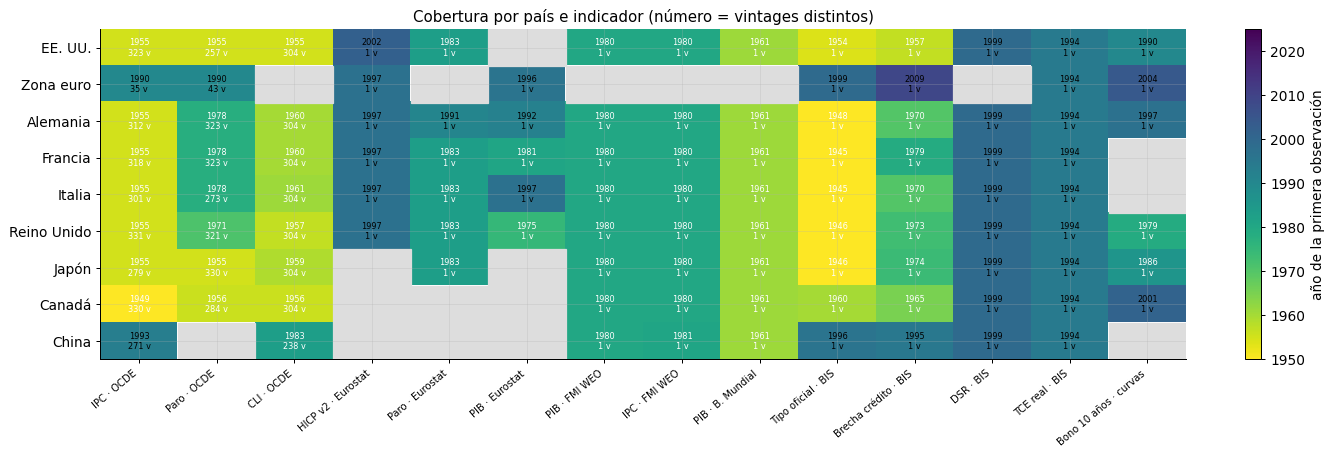

celdas con datos: 107 de 126


In [2]:
PAIS = {'US': 'EE. UU.', 'USA': 'EE. UU.', 'EA': 'Zona euro', 'EA20': 'Zona euro', 'XM': 'Zona euro', 'U2': 'Zona euro',
        'DE': 'Alemania', 'DEU': 'Alemania', 'FR': 'Francia', 'FRA': 'Francia', 'IT': 'Italia', 'ITA': 'Italia',
        'GB': 'Reino Unido', 'UK': 'Reino Unido', 'GBR': 'Reino Unido', 'JP': 'Japón', 'JPN': 'Japón',
        'CA': 'Canadá', 'CAN': 'Canadá', 'CN': 'China', 'CHN': 'China'}
FILAS = ['EE. UU.', 'Zona euro', 'Alemania', 'Francia', 'Italia', 'Reino Unido', 'Japón', 'Canadá', 'China']
REGLAS = [  # (indicador, patrón con el código de país en el grupo 'p')
    ('IPC · OCDE', r'^oecd:CP\.(?P<p>\w+)$'), ('Paro · OCDE', r'^oecd:UNEMP\.(?P<p>\w+)$'),
    ('CLI · OCDE', r'^oecd:LI_AA\.(?P<p>\w+)$'),
    ('HICP v2 · Eurostat', r'^eurostat:prc_hicp_minr\..*\.(?P<p>[A-Z]+)$'),
    ('Paro · Eurostat', r'^eurostat:une_rt_m\..*\.(?P<p>[A-Z]+)$'),
    ('PIB · Eurostat', r'^eurostat:namq_10_gdp\..*\.(?P<p>[A-Z]+)$'),
    ('PIB · FMI WEO', r'^imf:WEO\.(?P<p>\w+)\.NGDP_RPCH$'), ('IPC · FMI WEO', r'^imf:WEO\.(?P<p>\w+)\.PCPIPCH$'),
    ('PIB · B. Mundial', r'^wb:(?P<p>\w+)\.NY\.GDP'),
    ('Tipo oficial · BIS', r'^bis:WS_CBPOL\.M\.(?P<p>\w+)$'),
    ('Brecha crédito · BIS', r'^bis:WS_CREDIT_GAP\.Q\.(?P<p>\w+)\.'),
    ('DSR · BIS', r'^bis:WS_DSR\.Q\.(?P<p>\w+)\.'), ('TCE real · BIS', r'^bis:WS_EER\.M\.R\.B\.(?P<p>\w+)$'),
]
BONO10 = {'ust:PAR.10Y': 'EE. UU.', 'ecb:YC.AAA.10Y': 'Zona euro',
          'bbk:BBSIS.D.I.ZST.ZI.EUR.S1311.B.A604.R10XX.R.A.A._Z._Z.A': 'Alemania',
          'boe:NOM.10Y': 'Reino Unido', 'mof:JGB.10Y': 'Japón', 'boc:BOND.10Y': 'Canadá'}
cob = COB.set_index('id')
celdas = []
for ind, patron in REGLAS:
    for sid in cob.index:
        m = re.match(patron, sid)
        if m and m.group('p') in PAIS:
            celdas.append((PAIS[m.group('p')], ind, sid))
celdas += [(p, 'Bono 10 años · curvas', sid) for sid, p in BONO10.items() if sid in cob.index]
mapa = pd.DataFrame(celdas, columns=['pais', 'indicador', 'serie'])
mapa['inicio'] = pd.to_datetime(mapa['serie'].map(cob['inicio'])).dt.year
mapa['vintages'] = mapa['serie'].map(cob['n_vintages'])
cols = [r[0] for r in REGLAS] + ['Bono 10 años · curvas']
anio = mapa.groupby(['pais', 'indicador'])['inicio'].min().unstack().reindex(index=FILAS, columns=cols)
vint = mapa.groupby(['pais', 'indicador'])['vintages'].max().unstack().reindex(index=FILAS, columns=cols)

fig, ax = plt.subplots(figsize=(15, 5.2))
im = ax.imshow(anio.to_numpy(float), cmap='viridis_r', aspect='auto', vmin=1950, vmax=2025)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(len(FILAS)))
ax.set_yticklabels(FILAS)
for i in range(len(FILAS)):
    for j in range(len(cols)):
        a, v = anio.iat[i, j], vint.iat[i, j]
        if pd.notna(a):
            ax.text(j, i, f"{int(a)}\n{int(v)} v", ha='center', va='center', fontsize=6.5,
                    color='white' if a < 1990 else 'black')
        else:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color='#dddddd'))
fig.colorbar(im, ax=ax, label='año de la primera observación', fraction=0.025)
ax.set_title('Cobertura por país e indicador (número = vintages distintos)')
plt.tight_layout()
plt.show()
print(f"celdas con datos: {int(anio.notna().sum().sum())} de {anio.size}")

## 2. Ruptura de 2026 en el HICP: ECOICOP v2 frente a v1

Desde 2026 Eurostat publica el HICP con la clasificación **ECOICOP v2** (`prc_hicp_minr`; en el BCE, proveedor
`4D0`) y deja de actualizar la v1 (`prc_hicp_manr`, último dato 2025-12). En los meses que se solapan las dos tasas
anuales casi coinciden en la zona euro, pero no en algunos países: el gráfico muestra la diferencia v2 − v1 en
puntos porcentuales. La base guarda las dos series con su id.

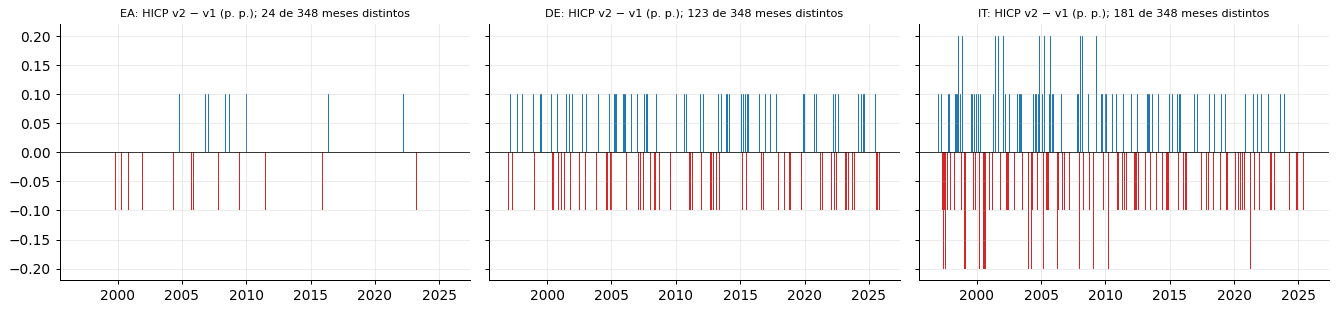

In [3]:
def ultima(sid):
    d = T[T['serie'] == sid].sort_values(['fecha_referencia', 'fecha_publicacion'])
    return d.drop_duplicates('fecha_referencia', keep='last').set_index('fecha_referencia')['valor']

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, geo in zip(axes, ['EA', 'DE', 'IT']):
    v2 = ultima(f'eurostat:prc_hicp_minr.M.RCH_A.TOTAL.{geo}')
    v1 = ultima(f'eurostat:prc_hicp_manr.M.RCH_A.CP00.{geo}')
    dif = (v2 - v1).dropna()
    ax.bar(dif.index, dif.values, width=25, color=np.where(dif.values >= 0, '#1f77b4', '#d62728'))
    ax.axhline(0, color='k', lw=.6)
    ax.set_title(f'{geo}: HICP v2 − v1 (p. p.); {int((dif.abs() > 1e-9).sum())} de {len(dif)} meses distintos',
                 fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

## 3. Zona euro de composición cambiante frente a EA20 y EA21

La zona euro pasa a 21 miembros en 2026. Eurostat publica tres agregados: `EA` (composición cambiante: cada mes con
los miembros de ese mes, lo que sabía un agente en su momento), `EA20` y `EA21` (composición fija, que reescriben la
historia con países que entonces no estaban). Para el agente se usa `EA` donde existe; la tasa de paro (`une_rt_m`)
y el ESI solo tienen agregados fijos. El gráfico muestra cuánto difieren los fijos del cambiante.

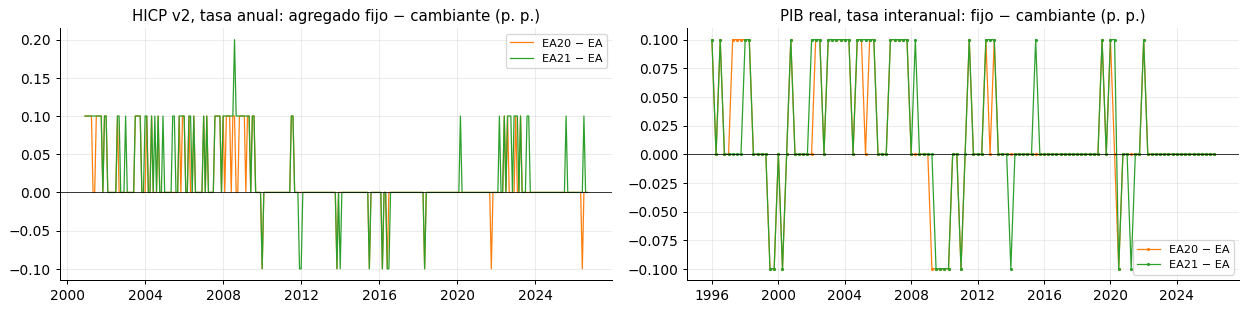

agregados europeos en el catálogo: ['EA', 'EA20', 'EA21', 'EU27_2020']


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
ea = ultima('eurostat:prc_hicp_minr.M.RCH_A.TOTAL.EA')
for geo, color in (('EA20', '#ff7f0e'), ('EA21', '#2ca02c')):
    d = (ultima(f'eurostat:prc_hicp_minr.M.RCH_A.TOTAL.{geo}') - ea).dropna()
    axes[0].plot(d.index, d.values, color=color, lw=1, label=f'{geo} − EA')
axes[0].axhline(0, color='k', lw=.6)
axes[0].set_title('HICP v2, tasa anual: agregado fijo − cambiante (p. p.)')
axes[0].legend()
ea = ultima('eurostat:namq_10_gdp.Q.CLV_PCH_SM.SCA.B1GQ.EA')
for geo, color in (('EA20', '#ff7f0e'), ('EA21', '#2ca02c')):
    d = (ultima(f'eurostat:namq_10_gdp.Q.CLV_PCH_SM.SCA.B1GQ.{geo}') - ea).dropna()
    axes[1].plot(d.index, d.values, color=color, lw=1, marker='.', ms=3, label=f'{geo} − EA')
axes[1].axhline(0, color='k', lw=.6)
axes[1].set_title('PIB real, tasa interanual: fijo − cambiante (p. p.)')
axes[1].legend()
plt.tight_layout()
plt.show()
geos = {s.rsplit('.', 1)[1] for s in CAT if s.startswith('eurostat:')}
print('agregados europeos en el catálogo:', sorted(g for g in geos if g.startswith(('EA', 'EU'))))

## 3b. Series por defecto para los agentes y fechas por época

Para que un agente no tenga que elegir entre versiones, la zona euro de **composición cambiante** tiene alias:
`HICP_EA` (HICP empalmado por fecha de publicación: ECOICOP v1 en los periodos publicados antes de la primera
versión de v2 y v2 después, `eurostat:HICP_EMP.EA`), `PIB_EA` (`namq_10_gdp` `EA`) y `PARO_EA` (BCE `LFSI` `U2`).
A la derecha, el retraso de publicación que aplica la regla (días desde el inicio del periodo) con los **tramos por
época** de `lags.yaml`: el paro pasa del fin de M+2 a 1M10D + hábil TARGET en 2012 y el PIB de los agregados de t+71
a t+45 (2003) y a t+30 (2016), verificados con notas de prensa archivadas de Eurostat (el test exige que la regla
nunca caiga antes de la publicación real, también en las fronteras).

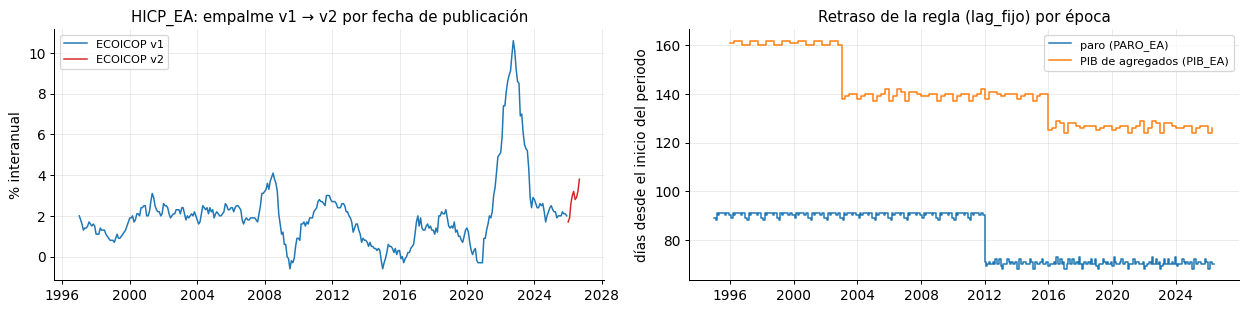

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
emp = T[T['serie'] == cat_mod.resolver('HICP_EA', CAT)]
emp = emp.sort_values('fecha_referencia')
for tramo, color in (('tramo v1', '#1f77b4'), ('tramo v2', '#d62728')):
    sel = emp[emp['nota'].str.contains(tramo, regex=False)]
    axes[0].plot(sel['fecha_referencia'], sel['valor'], color=color, lw=1.2, label=tramo.replace('tramo ', 'ECOICOP '))
axes[0].set_title('HICP_EA: empalme v1 → v2 por fecha de publicación')
axes[0].set_ylabel('% interanual')
axes[0].legend(loc='upper left')
for sid, etiqueta in ((cat_mod.resolver('PARO_EA', CAT), 'paro (PARO_EA)'),
                      (cat_mod.resolver('PIB_EA', CAT), 'PIB de agregados (PIB_EA)')):
    d = T[T['serie'] == sid].sort_values(['fecha_referencia', 'fecha_publicacion'])
    d = d.drop_duplicates('fecha_referencia', keep='first')
    d = d[d['metodo_publicacion'] == 'lag_fijo']
    axes[1].step(d['fecha_referencia'], (d['fecha_publicacion'] - d['fecha_referencia']).dt.days, where='post',
                 lw=1.2, label=etiqueta)
axes[1].set_title('Retraso de la regla (lag_fijo) por época')
axes[1].set_ylabel('días desde el inicio del periodo')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

## 4. Abanicos por edición: CLI de la OCDE y WEO del FMI

La OCDE revisa en cada edición mensual buena parte de la historia del indicador adelantado (CLI): de mediana el
44-48 % de los periodos comunes con la edición anterior (medido en EE. UU. y Alemania); el valor de 2008 que vio un
agente en 2008 no es el de hoy. El abanico muestra el CLI de EE. UU. tal como se publicó en varias ediciones
(cada línea acaba en el último mes que esa edición conocía). Del **WEO** del FMI solo hay hoy una edición (2026-10,
API SDMX): las ediciones 2008-2025 de DBnomics quedan fuera porque su `robots.txt` lo prohíbe (comprobado de nuevo el
2026-10-13), así que el abanico del WEO se reduce a una edición hasta que se consiga el archivo por edición (ver ficha
`imf_weo`). Las series del WEO solo traen datos de años anteriores al de la edición; la estimación del año en curso y
las proyecciones van a series propias `imf:WEO.<país>.<concepto>.PROY.H<h>`.

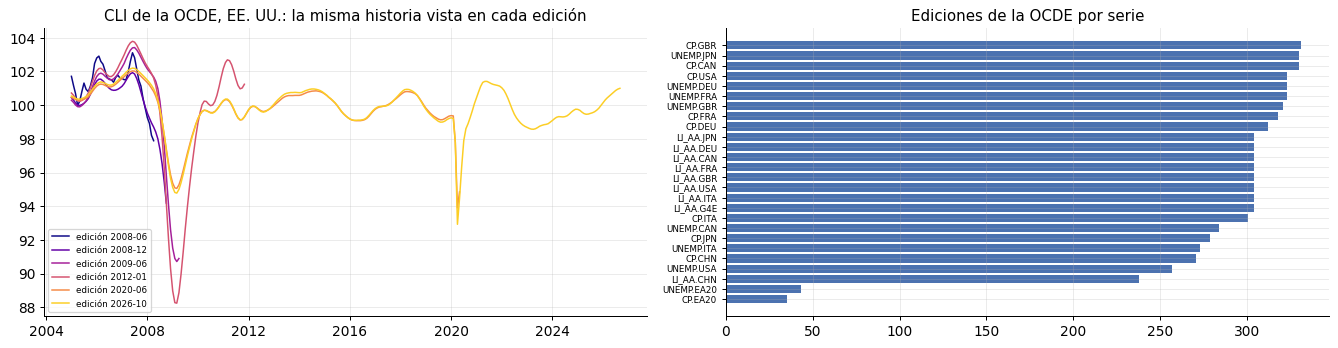

ediciones del WEO cargadas: ['2026-10'] | series: 280


In [6]:
def vista_edicion(sid, edicion):
    d = T[(T['serie'] == sid) & (T['vintage'] <= edicion)].sort_values(['fecha_referencia', 'vintage'])
    return d.drop_duplicates('fecha_referencia', keep='last').set_index('fecha_referencia')['valor']

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
cli = T[T['serie'] == 'oecd:LI_AA.USA']
ediciones = ['2008-06', '2008-12', '2009-06', '2012-01', '2020-06', '2026-10']
for ed, color in zip(ediciones, plt.cm.plasma(np.linspace(0, .9, len(ediciones)))):
    if (cli['vintage'] <= ed).any():
        v = vista_edicion('oecd:LI_AA.USA', ed)
        v = v[v.index >= '2005-01-01']
        axes[0].plot(v.index, v.values, color=color, lw=1.2, label=f'edición {ed}')
axes[0].set_title('CLI de la OCDE, EE. UU.: la misma historia vista en cada edición')
axes[0].legend(fontsize=7)
n_ed = T[T['serie'].str.startswith('oecd:')].groupby('serie')['vintage'].nunique().sort_values()
axes[1].barh(n_ed.index.str.replace('oecd:', ''), n_ed.values, color='#4c72b0')
axes[1].set_title('Ediciones de la OCDE por serie')
axes[1].tick_params(axis='y', labelsize=7)
plt.tight_layout()
plt.show()
weo = T[T['serie'].str.startswith('imf:')]
print('ediciones del WEO cargadas:', sorted(weo['vintage'].unique()), '| series:', weo['serie'].nunique())

## 5. Philadelphia Fed antes de ALFRED

ALFRED solo tiene vintages del PIB real (`GDPC1`) desde 1991-12-04. La RTDSM de la Fed de Filadelfia conserva las
matrices de vintages trimestrales desde 1965 (`ROUTPUT`): el cargador `philly_rtdsm` añade **solo** los vintages
anteriores al primero de ALFRED, con prioridad por debajo de las fuentes vivas. PCPI, EMPLOY y RUC no aportan
filas: ALFRED ya empieza antes que la RTDSM. El gráfico sigue el crecimiento trimestral anualizado de algunos
trimestres a lo largo de los vintages: la primera estimación y las revisiones que vio un agente.

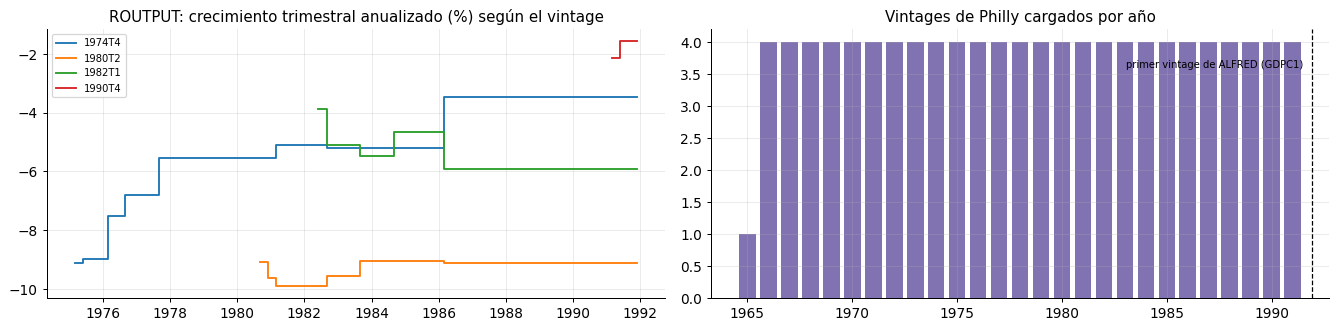

filas de philly:ROUTPUT: 971 | vintages: 105


In [7]:
ph = T[T['serie'] == 'philly:ROUTPUT'].copy()
ph['vint'] = pd.to_datetime(ph['fecha_publicacion'])
piv = ph.pivot_table(index='vint', columns='fecha_referencia', values='valor', aggfunc='last').sort_index().ffill()
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for q, color in zip(['1974-10-01', '1980-04-01', '1982-01-01', '1990-10-01'], colores):
    q = pd.Timestamp(q)
    prev = q - pd.DateOffset(months=3)
    if q in piv and prev in piv:
        g = ((piv[q] / piv[prev]) ** 4 - 1).dropna() * 100
        axes[0].step(g.index, g.values, where='post', color=color, label=f'{q.year}T{(q.month - 1) // 3 + 1}')
axes[0].set_title('ROUTPUT: crecimiento trimestral anualizado (%) según el vintage')
axes[0].legend(fontsize=8)
por_anio = ph.groupby(ph['vint'].dt.year)['vintage'].nunique()
axes[1].bar(por_anio.index, por_anio.values, color='#8172b2')
axes[1].axvline(1991.9, color='k', ls='--', lw=1)
axes[1].text(1991.5, por_anio.max() * .9, 'primer vintage de ALFRED (GDPC1)', ha='right', fontsize=8)
axes[1].set_title('Vintages de Philly cargados por año')
plt.tight_layout()
plt.show()
print('filas de philly:ROUTPUT:', len(ph), '| vintages:', ph['vintage'].nunique())

## 6. Retraso de publicación medido por fuente

Días naturales entre `fecha_referencia` y la primera `fecha_publicacion` de cada periodo (mediana por serie). Las
diarias de mercado y las curvas se ven en uno o dos días; las mensuales de la OCDE y Eurostat en uno o dos meses;
el BIS trimestral y el Banco Mundial anual son los más lentos (lags conservadores declarados en `lags.yaml`).

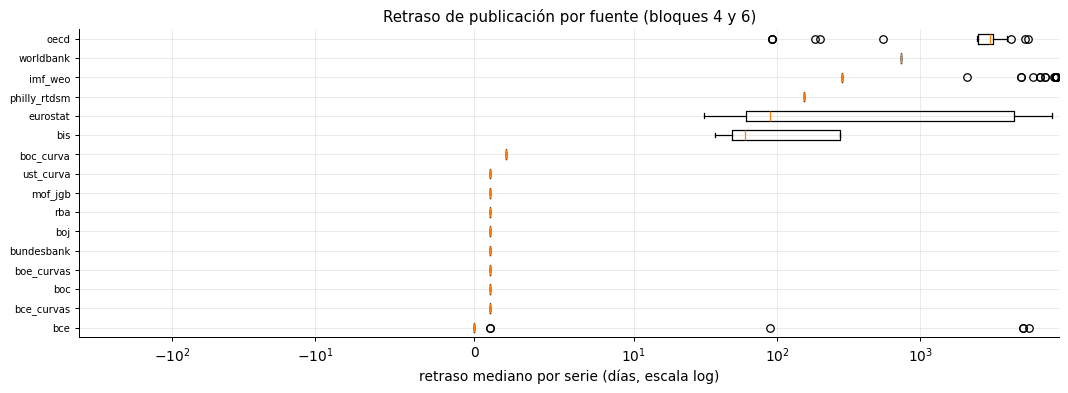

In [8]:
COB['fuente_cat'] = COB['id'].map(lambda s: CAT[s]['fuente'])
orden = COB.groupby('fuente_cat')['lag_mediano_dias'].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
datos = [COB.loc[COB['fuente_cat'] == f, 'lag_mediano_dias'].dropna().to_numpy() for f in orden]
ax.boxplot(datos, vert=False, showfliers=True)
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden, fontsize=8)
ax.set_xscale('symlog', linthresh=10)
ax.set_xlabel('retraso mediano por serie (días, escala log)')
ax.set_title('Retraso de publicación por fuente (bloques 4 y 6)')
plt.tight_layout()
plt.show()

## Conclusiones

- La base gana las fuentes oficiales del perímetro: zona euro (BCE, Eurostat), G7 y China (OCDE con ediciones,
  BIS, FMI), el resto del mundo anual (Banco Mundial) y las curvas soberanas oficiales de EE. UU., zona euro, Japón,
  Canadá y Reino Unido. Prioridad al unir: ALFRED > académicos > FRED vivo > fuentes oficiales > Philly > Fase 1.
- Huecos que quedan: CLI de la zona euro (la OCDE ya no lo publica; `oecd:LI_AA.G4E` son los cuatro grandes
  europeos, no la zona euro) y paro de China en la OCDE, DSR de China, ediciones históricas del WEO
  (DBnomics vetado por `robots.txt`), BoE IADB (vetado por `robots.txt`; el Reino Unido se cubre con la OCDE y la
  curva del BoE) e historia anterior a 2001 de BoC y a 2011 de RBA.
- La ruptura ECOICOP v2 es pequeña en la zona euro y mayor en algunos países (Italia): el empalme por fecha de
  publicación (`HICP_EA`, `eurostat:HICP_EMP.<geo>`) lleva nota y tramo en cada fila. Los agregados fijos EA20/EA21
  reescriben la historia; los alias `HICP_EA`, `PIB_EA` y `PARO_EA` apuntan a la zona euro cambiante.
- La OCDE revisa buena parte de la historia del CLI en cada edición: usarlo con su vintage es imprescindible para
  no filtrar información futura.